In [24]:
!pip install control
!pip install nbformat

In [96]:
import control as ct
import plotly.graph_objects as go
import plotly.io as pio
import matplotlib.pyplot as plt
import numpy as np

pio.renderers.default = "vscode"

## Tarefa 1:

In [93]:
Gv = ct.tf([0.05], [3, 1],  name="Gv", inputs="U",  outputs="Qv")
Gt = ct.tf([20],   [60, 1], name="Gt", inputs="Q",  outputs="H")
Hm = ct.tf([1],    [10, 1], name="Hm", inputs="H",  outputs="Hmed")
Hm2 = ct.tf([1],[30,1])
Hm3 = ct.tf([1],[1,1])

In [51]:
Gma1 = Gv*Gt # Nivel real do tanque
Gma2 = Gv*Gt*Hm # Nivel que o controlador vai exengar
Gma3 = Gv*Gt*Hm2 # Nivel que o controlador vai exengar
Gma4 = Gv*Gt*Hm3 # Nivel que o controlador vai exengar

In [60]:
info = ct.step_info(Gma1)
info

{'RiseTime': 129.7820688778462,
 'SettlingTime': 238.63154600120103,
 'SettlingMin': 0.9018312266438707,
 'SettlingMax': 1.0,
 'Overshoot': 0.0,
 'Undershoot': 0.0,
 'Peak': 0.9989473684210517,
 'PeakTime': 414.46531673892815,
 'SteadyStateValue': 1.0}

In [52]:
t_step,y_step = ct.step_response(Gma1)
z_step,k_step = ct.step_response(Gma2)
e_step,b_step = ct.step_response(Gma3)
j_step,o_step = ct.step_response(Gma4)

In [53]:
fig1 = go.Figure()
grafico_step1=go.Scatter(x=t_step,
                        y=y_step,
                        name='Gma1(s)',
                        mode='lines',
                        line=dict(color="blue", width=4))

grafico_step2 = go.Scatter(x=z_step,
                        y=k_step,
                        name='Gma2(s)',
                        mode='markers',
                        line=dict(color="red", width=4))
grafico_step3 = go.Scatter(x=e_step,
                        y=b_step,
                        name='Gma2(s)',
                        mode='markers',
                        line=dict(color="yellow", width=4))
grafico_step4 = go.Scatter(x=j_step,
                        y=o_step,
                        name='Gma2(s)',
                        mode='markers',
                        line=dict(color="green", width=4))

In [54]:
fig1.add_trace(grafico_step1)
fig1.add_trace(grafico_step2)
fig1.add_trace(grafico_step3)
fig1.add_trace(grafico_step4)


Tempo de resposta ao analisar o gráfico, assumindo como 2%, o Gma1 = 238.63 s e Gma2 = 250 s; 
De fato, não existe sobressinal pois são polos reais e negativos, então a resposta é sobreamortecida;
Ganho estático é 1;
Polos −1/3, −1/60 (e −1/10 com o Hm), porém existe uma dominancia de polos por conta do polo de -1/60;
Fase não mínima, como não há zeros no semiplano direito, a fase não mínima, não existe.

Comente sobre o papel da dinâmica do transmissor de nível e do seu filtro de amortecimento:
Sobre essa particuladirade, esse filtro apenas "envia" a resposta para o controlador de uma forma menos "caótica" atrasada em t=10s. O que acontece caso esse valor suba ainda mais, a resposta final que chagará ao controlador será ainda mais atrasada porém ela será cada vez menos instável, conforme aumentando o valor de t. E se esse valor diminuir, o controlador saberá praticamente instantaneamente qual valor deve ser ajustado, porém se torna um controlador muito sensível a ruidos. Ou seja depende muito desse tradeoff de filtrar os ruídos e ter respostas mais rápidas.

## Tarefa 2:

/usr/local/lib/python3.13/dist-packages/control/rlocus.py:202: FutureWarning:

root_locus() return value of roots, gains is deprecated; use root_locus_map()



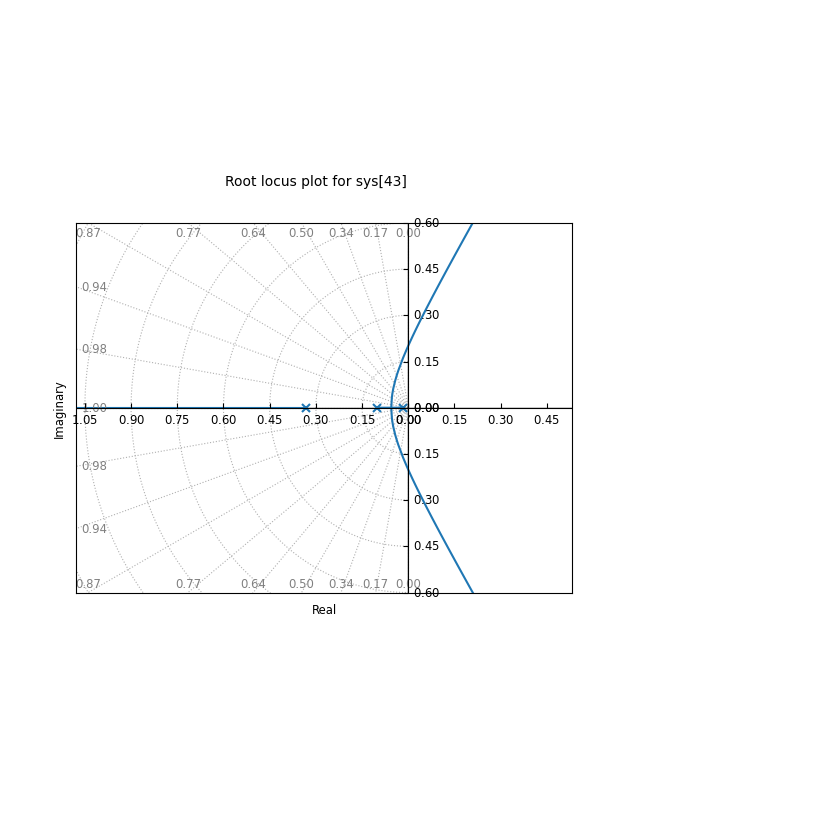

In [55]:
root_array, kvect=ct.root_locus(Gma2, plot=True)

## Tarefa 3:

Erro nulo em regime permanente: Adicionar um integrador (1/s)! 
Máximo sobressinal de 5%
Tempo de acomodação 20% MENOR que o tempo em malha aberta: 238.63 * 0,8 = 190,90

In [92]:
K = 1.34

C = ct.tf([1,0.0272],[1,0], name="C", inputs="E", outputs="U")
Cs = K*C
# tive que fazer dessa forma por que ao fazer uma operacao com o C, os nomes se perdiam...
C_b  = ct.tf(Cs.num[0][0], Cs.den[0][0], name="C", inputs="E", outputs="U") 

print (Cs)


<TransferFunction>: sys[103]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

  1.34 s + 0.03645
  ----------------
         s


/usr/local/lib/python3.13/dist-packages/control/rlocus.py:202: FutureWarning:

root_locus() return value of roots, gains is deprecated; use root_locus_map()



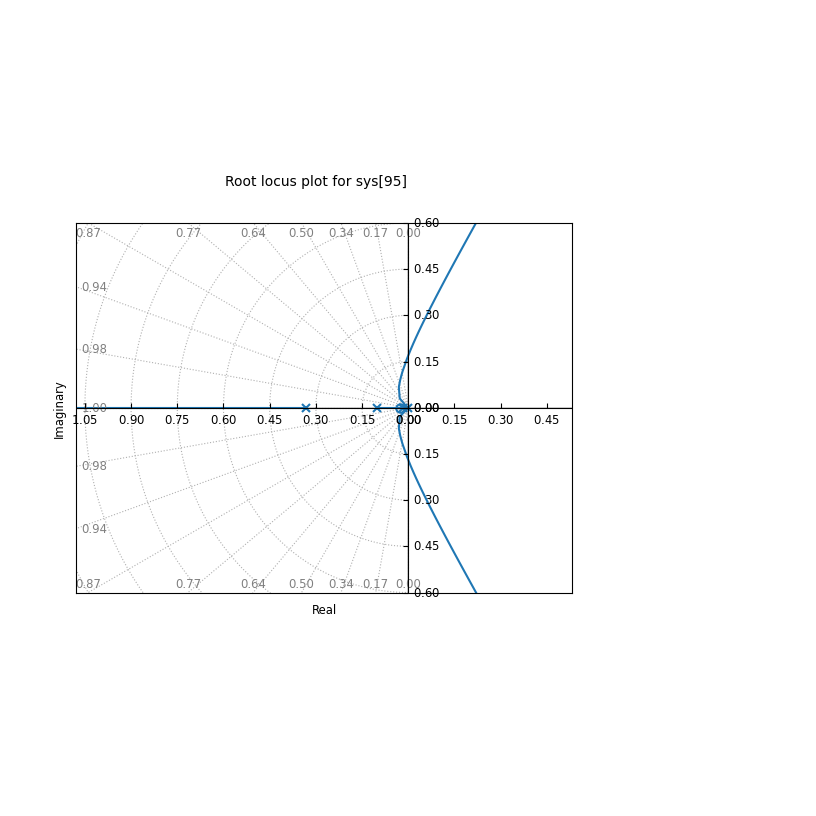

In [85]:
root_array, kvect=ct.root_locus(C*Gma2, plot=True)

In [ ]:
Gm = Cs*Gma2
Gmf = ct.feedback(Gm, 1, sign=-1)
ct.poles(Gmf)

array([-0.34203479+0.j        , -0.06701459+0.j        ,
       -0.02047531+0.02154461j, -0.02047531-0.02154461j])

/usr/local/lib/python3.13/dist-packages/control/rlocus.py:202: FutureWarning:

root_locus() return value of roots, gains is deprecated; use root_locus_map()



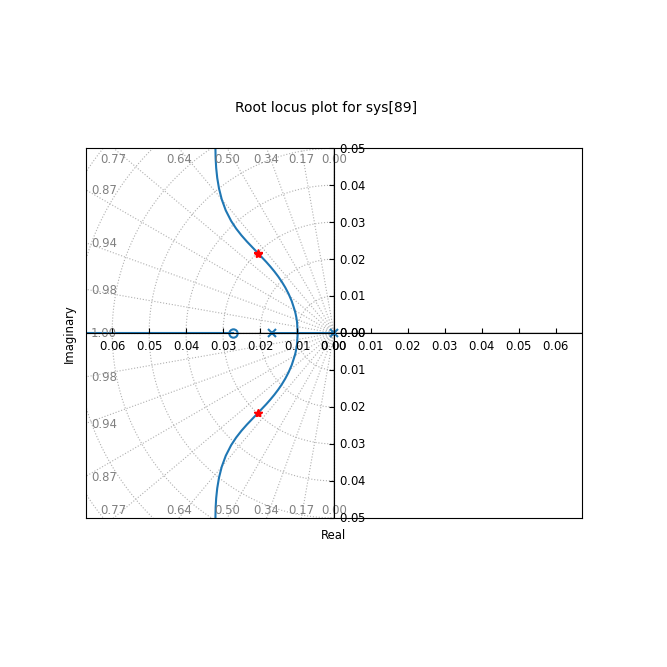

In [81]:
ct.root_locus(C*Gma2, plot=True)
plt.xlim(-0.05, 0.05)
plt.ylim(-0.05, 0.05)
plt.plot(-0.0205, 0.0215, 'r*')
plt.plot(-0.0205, -0.0215, 'r*')
plt.plot(-0.02047531, 0.02154461, 'r*')
plt.plot(-0.02047531, -0.02154461, 'r*')
plt.show()

Basedo nos polos da Gmf ao utilizar 'ct.poles(Gmf)', podemos ver que eles contém alguns a mais, porém ainda contém os polos que são desejados, então, o nosso controlador está definido corretamente!

In [90]:
soma1 = ct.summing_junction(inputs=["Hsp", "-Hmed"], output="E", name="soma_erro")
soma2  = ct.summing_junction(inputs=["Qv", "Qp"],     output="Q", name="soma_vazao")

In [95]:
conexao = ct.interconnect([soma1,C_b,Gv,soma2,Gt,Hm],
                          inputs=['Qp','Hsp'],
                          outputs=['H','U'])
print (conexao)

<LinearICSystem>: sys[116]
Inputs (2): ['Qp', 'Hsp']
Outputs (2): ['H', 'U']
States (4): ['C_x[0]', 'Gv_x[0]', 'Gt_x[0]', 'Hm_x[0]']

Subsystems (6):
 * <StateSpace soma_erro: ['Hsp', 'Hmed'] -> ['E'], dt=None>
 * <StateSpace C: ['E'] -> ['U']>
 * <StateSpace Gv: ['U'] -> ['Qv']>
 * <StateSpace soma_vazao: ['Qv', 'Qp'] -> ['Q'], dt=None>
 * <StateSpace Gt: ['Q'] -> ['H']>
 * <StateSpace Hm: ['H'] -> ['Hmed']>

Connections:
 * soma_erro.Hsp <- Hsp
 * soma_erro.Hmed <- Hm.Hmed
 * C.E <- soma_erro.E
 * Gv.U <- C.U
 * soma_vazao.Qv <- Gv.Qv
 * soma_vazao.Qp <- Qp
 * Gt.Q <- soma_vazao.Q
 * Hm.H <- Gt.H

Outputs:
 * H <- Gt.H
 * U <- C.U

A = [[ 0.          0.          0.         -0.1       ]
     [ 0.036448   -0.33333333  0.         -0.134     ]
     [ 0.          0.01666667 -0.01666667  0.        ]
     [ 0.          0.          0.33333333 -0.1       ]]

B = [[0.   1.  ]
     [0.   1.34]
     [1.   0.  ]
     [0.   0.  ]]

C = [[ 0.          0.          0.33333333  0.        ]
     [ 0.03

In [104]:
t = np.arange(0, 900, 0.3)    
sinal = 0.5 * np.ones(len(t))   
degraus = np.zeros(len(t))
degraus[t < 300] = 40
degraus[(t >= 300) & (t < 600)] = 60
degraus[t >= 600] = 50

U = np.vstack([sinal, degraus])
print(U.shape)

(2, 3000)


In [102]:
Gfinal = ct.forced_response(conexao,t,U)

In [112]:
fig2 = go.Figure()
grafico=go.Scatter(     x=t,
                        y=Gfinal.outputs[0],
                        name='Nivel H(t)',
                        mode='lines',
                        line=dict(color="blue", width=4))
grafico2=go.Scatter(     x=t,
                        y=degraus,
                        name='Referência Hsp',
                        mode='lines',
                        line=dict(color="red", dash="dash"))
fig2.add_trace(grafico)
fig2.add_trace(grafico2)


In [ ]:
fig3 = go.Figure()
graficop=go.Scatter(    x=t,
                        y=Gfinal.outputs[1],
                        name='Nivel U(t)',
                        mode='lines',
                        line=dict(color="blue", width=4)

)
fig3.add_trace(graficop)
fig3.add_hline(y=0,   line_dash="dash", line_color="gray", annotation_text="0% (fechada)")
fig3.add_hline(y=100, line_dash="dash", line_color="gray", annotation_text="100% (aberta)")